In [1]:
import os
import pandas as pd
import snowflake.connector
from dotenv import load_dotenv

load_dotenv()
conn = snowflake.connector.connect(
    user=os.getenv("SNOWFLAKE_USER"),
    password=os.getenv("SNOWFLAKE_PASSWORD"),
    account=os.getenv("SNOWFLAKE_ACCOUNT"),
    warehouse=os.getenv("SNOWFLAKE_WAREHOUSE"),
    database=os.getenv("SNOWFLAKE_DATABASE"),
    role=os.getenv("SNOWFLAKE_ROLE"),
)
df = conn.cursor().execute("select * from raw.flights").fetch_pandas_all()
df.columns = df.columns.str.lower()

In [2]:
df.columns = df.columns.str.lower()
df["airport"] = df["flight_leg_identifier__departure_airport_iata"].where(
    df["direction"] == "departures",
    df["flight_leg_identifier__arrival_airport_iata"],
)
df.groupby(["airport", "direction"]).size().unstack()

direction,arrivals,departures
airport,,
ARN,1058,1049
BMA,66,66
GOT,233,227
KRN,6,6
LLA,46,46
MMX,67,68
OSD,17,19
RNB,16,17
UME,44,45


In [3]:
# SIze and first rows
print(df.shape)
df.head()

(3172, 49)


,flight_id,departure_airport_swedish,departure_airport_english,di_indicator,flight_leg_identifier__callsign,flight_leg_identifier__flight_id,flight_leg_identifier__flight_departure_date_utc,flight_leg_identifier__departure_airport_iata,flight_leg_identifier__arrival_airport_iata,flight_leg_identifier__departure_airport_icao,...,location_and_status__gate_action_english,location_and_status__gate_open_utc,location_and_status__gate_close_utc,departure_time__actual_utc,departure_time__estimated_utc,baggage__estimated_first_bag_utc,direction,query_date,fetched_at,airport
0,FR915,Rom FCO,Rome FCO,S,RYR97XH,FR915,2026-10-06 17:00:00-07:00,FCO,ARN,LIRF,...,NaN,NaT,NaT,NaT,NaT,NaT,arrivals,2026-10-07,2026-10-09 01:16:01.402031-07:00,ARN
1,FR4464,Birmingham,Birmingham,I,RYR4464,FR4464,2026-10-06 17:00:00-07:00,BHX,ARN,EGBB,...,NaN,NaT,NaT,NaT,NaT,NaT,arrivals,2026-10-07,2026-10-09 01:16:01.402031-07:00,ARN
2,FR3008,Dublin,Dublin,I,RYR3008,FR3008,2026-10-06 17:00:00-07:00,DUB,ARN,EIDW,...,NaN,NaT,NaT,NaT,NaT,NaT,arrivals,2026-10-07,2026-10-09 01:16:01.402031-07:00,ARN
3,FR7619,Palma,Palma,S,RYR9JP,FR7619,2026-10-06 17:00:00-07:00,PMI,ARN,LEPA,...,NaN,NaT,NaT,NaT,NaT,NaT,arrivals,2026-10-07,2026-10-09 01:16:01.402031-07:00,ARN
4,FR7694,Chania,Chania,S,RYR7694,FR7694,2026-10-06 17:00:00-07:00,CHQ,ARN,LGSA,...,NaN,NaT,NaT,NaT,NaT,NaT,arrivals,2026-10-07,2026-10-09 01:16:01.402031-07:00,ARN


In [4]:
# Column types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3172 entries, 0 to 3171
Data columns (total 49 columns):
 #   Column                                            Non-Null Count  Dtype                              
---  ------                                            --------------  -----                              
 0   flight_id                                         3172 non-null   str                                
 1   departure_airport_swedish                         1591 non-null   str                                
 2   departure_airport_english                         1591 non-null   str                                
 3   di_indicator                                      3172 non-null   str                                
 4   flight_leg_identifier__callsign                   3172 non-null   str                                
 5   flight_leg_identifier__flight_id                  3172 non-null   str                                
 6   flight_leg_identifier__flight_departure_dat

In [5]:
# Missing values (share of rowns, top 15 columns)
df.isna().mean().sort_values(ascending=False).head(15)

departure_time__estimated_utc               0.954288
baggage__estimated_first_bag_utc            0.925914
location_and_status__gate_open_utc          0.645649
baggage__last_bag_utc                       0.622951
baggage__first_bag_utc                      0.619483
check_in__check_in_desk_to                  0.605927
check_in__check_in_desk_from                0.605927
location_and_status__gate_action_swedish    0.601828
location_and_status__gate_action_english    0.601828
location_and_status__gate_action            0.596154
location_and_status__gate_close_utc         0.595523
departure_time__actual_utc                  0.594578
check_in__check_in_status_english           0.593001
check_in__check_in_status_swedish           0.593001
check_in__check_in_status                   0.593001
dtype: float64

In [6]:
df.drop(columns=[c for c in df.columns if c.startswith("_dlt")]).duplicated().sum()

np.int64(0)

In [7]:
# numeric columns
df.describe()

,check_in__check_in_desk_from,check_in__check_in_desk_to
count,1250.000000,1250.000000
mean,37.545600,43.035200
std,26.530402,29.642147
min,1.000000,1.000000
25%,17.000000,20.000000
50%,30.000000,31.000000
75%,71.000000,80.000000
max,87.000000,90.000000


In [8]:
# query dates and value count 
df["query_date"].value_counts()

query_date
2026-10-08    1069
2026-10-07    1052
2026-10-09    1051
Name: count, dtype: int64

In [9]:
# query dates, airport and direction
df.groupby(["query_date", "airport", "direction"]).size().unstack()

direction           arrivals  departures
query_date airport                      
2026-10-07 ARN           349         346
           BMA            23          23
           GOT            77          76
           KRN             2           2
           LLA            15          15
           MMX            22          22
           OSD             6           7
           RNB             6           6
           UME            15          16
           VBY            12          12
2026-10-08 ARN           353         354
           BMA            22          22
           GOT            82          79
           KRN             2           2
           LLA            15          14
           MMX            23          23
           OSD             6           6
           RNB             6           6
           UME            14          14
           VBY            13          13
2026-10-09 ARN           356         349
           BMA            21          21
           GOT            74          72
           KRN             2           2
           LLA            16          17
           MMX            22          23
           OSD             5           6
           RNB             4           5
           UME            15          15
           VBY            13          13

### Checking for duplicates

In [10]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Checking for deleted rows 
col = "location_and_status__flight_leg_status_english"
df[col].str.split().str[0].value_counts(dropna=False)

location_and_status__flight_leg_status_english
Landed       872
Departed     862
Deleted      359
Cancelled     22
Scheduled      6
Name: count, dtype: int64

In [ ]:
# Checking if the deleted rows seem to be a data loading error
col = "location_and_status__flight_leg_status_english"
(df.assign(status=df[col].str.split().str[0])
   .groupby(["airport", "status"]).size().unstack(fill_value=0))

status,Cancelled,Deleted,Departed,Landed,Scheduled
airport,,,,,
ARN,19,241,571,571,0
BMA,0,32,29,29,0
GOT,2,42,133,137,0
KRN,0,0,4,4,0
LLA,0,9,22,26,2
MMX,0,21,31,35,3
OSD,0,0,13,12,0
RNB,0,6,9,9,0
UME,1,2,28,27,1


### Conclussion on deleted rows
From teh data around 15% are deleted flights from all airports except 2. 

<Axes: xlabel='airport'>

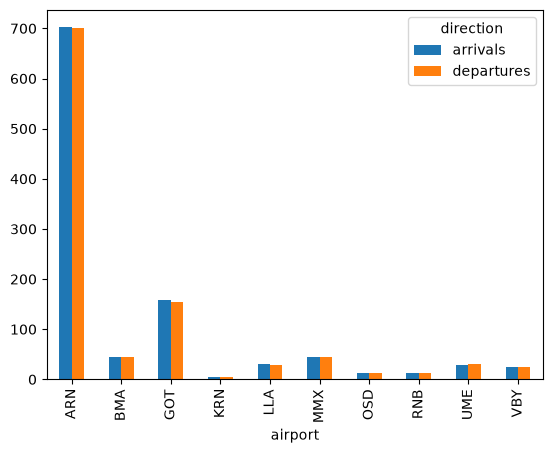

In [ ]:
df.groupby(["airport", "direction"]).size().unstack().plot.bar()